# Gabarito — Espectrograma e transformada Q

**Notebook complementar:** `intro-4-qtransform.ipynb`  
**Tema:** evolução da frequência durante a fusão de sistemas binários de buracos negros.

Este gabarito resolve as **três questões de verificação** e as **duas atividades práticas**. Ele pode ser executado de forma independente no VS Code ou JupyterLab, desde que `pycbc` e `gwpy` estejam instalados no kernel selecionado.

**Referência:** notebook original sobre a transformada Q. Os exemplos utilizam o modelo `SEOBNRv2`, taxa de amostragem de 4096 Hz, distância de 100 Mpc e frequência mínima de 40 Hz.

## Preparação — Reproduzir o sistema original (10 + 10 massas solares)

Mantemos os parâmetros e a construção da série temporal utilizados na atividade. Para que a comparação com o segundo sistema seja mais clara, geramos **uma única realização de ruído** e a reutilizamos nos dois casos.

**Observação:** no notebook original, `t0=4` é o **início da série simulada**. Como as formas de onda têm durações diferentes, as fusões não ocorrerão exatamente no mesmo instante do gráfico quando as duas séries começarem em 4 s.

/Users/ronaimac/miniforge3/envs/ix-sct/lib/python3.12/importlib/__init__.py:90: UserWarning: Wswiglal-redir-stdio:
----------------------------------------------------------------
SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal
----------------------------------------------------------------

  return _bootstrap._gcd_import(name[level:], package, level)
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


Sistema 10 + 10: duração = 0.925 s
Instante aproximado de maior amplitude: 4.892 s


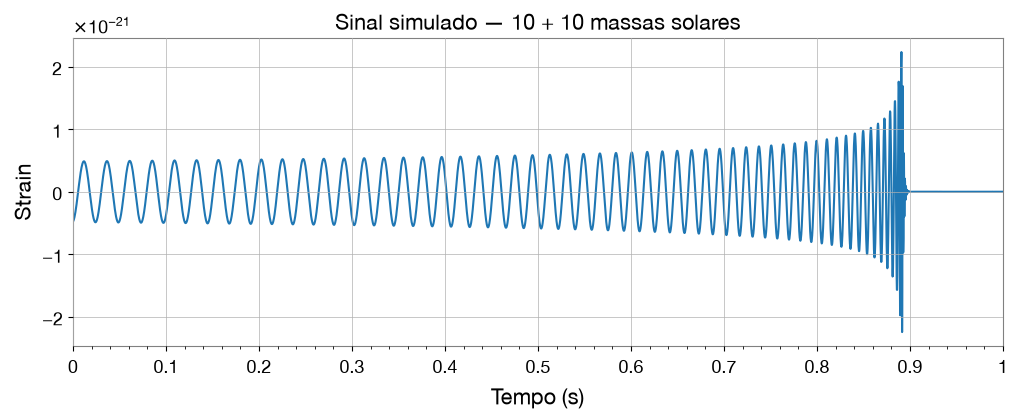

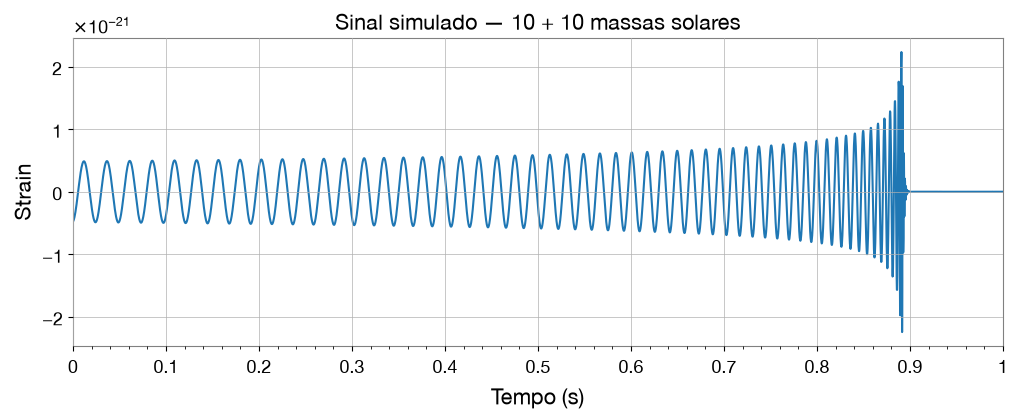

In [1]:
# -- Importar as bibliotecas e definir os parâmetros do exemplo
import numpy as np
import matplotlib.pyplot as plt
from pycbc.waveform import get_td_waveform
from gwpy.timeseries import TimeSeries

plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 13})

fs = 4096                  # frequência de amostragem (Hz)
apx = 'SEOBNRv2'            # modelo da forma de onda
distancia = 100            # Mpc
f_inicial = 40             # Hz
t0 = 4                     # início do sinal no gráfico (s)

# -- Sistema original: 10 + 10 massas solares
hp10, hc10 = get_td_waveform(
    approximant=apx, mass1=10, mass2=10,
    delta_t=1.0/fs, distance=distancia, f_lower=f_inicial
)
cbc10 = TimeSeries(np.asarray(hp10), dt=1/fs, t0=t0)

# -- Usar a mesma realização de ruído nos dois sistemas
rng = np.random.default_rng(2026)
noise_arr = rng.random(fs*8) * 1e-24   # como no notebook original
noise = TimeSeries(noise_arr, dt=1.0/fs)
data10 = noise.inject(cbc10)

# -- Mostrar informações relevantes
pico10 = t0 + np.argmax(np.abs(np.asarray(hp10))) / fs
print(f'Sistema 10 + 10: duração = {len(hp10)/fs:.3f} s')
print(f'Instante aproximado de maior amplitude: {pico10:.3f} s')

fig10 = data10.plot(xlim=(4, 5))
ax10 = fig10.gca()
ax10.set_xlabel('Tempo (s)')
ax10.set_ylabel('Strain')
ax10.set_title('Sinal simulado — 10 + 10 massas solares')
fig10

## Questões de verificação

### 1. Qual é a frequência do sinal cerca de 0,8 s antes da fusão?

**Resposta:** aproximadamente **40–45 Hz**, estimando visualmente a posição da faixa mais intensa no espectrograma original. É um valor próximo da frequência inicial de 40 Hz usada para gerar a forma de onda.

Como a frequência evolui continuamente, não há uma única frequência para todo o trecho inicial. O valor exato depende de qual instante é escolhido e da resolução tempo-frequência do gráfico.

### 2. Qual é a frequência do sinal próximo ao instante da fusão?

**Resposta:** a frequência cresce até a região de **centenas de hertz**. No espectrograma original, a faixa mais visível imediatamente antes da fusão situa-se aproximadamente em **150–250 Hz**, embora a energia se espalhe por frequências mais altas na região final.

Essa é uma **estimativa visual**, não uma frequência única e exata: as últimas oscilações variam rapidamente, e a transformada Q possui resolução limitada em tempo e frequência.

### 3. Por que a frequência aumenta à medida que nos aproximamos da fusão?

**Resposta:** o sistema binário emite ondas gravitacionais e perde energia e momento angular orbitais. Com isso, a separação entre os corpos diminui e a frequência orbital aumenta. Para uma órbita aproximadamente circular, a frequência dominante da onda gravitacional é aproximadamente o dobro da frequência orbital:

$$f_{\mathrm{GW}}\simeq 2f_{\mathrm{orb}}.$$

Na aproximação newtoniana, para massa total fixa,

$$f_{\mathrm{orb}}=\frac{1}{2\pi}\sqrt{\frac{GM}{r^3}}.$$

Assim, à medida que a separação $r$ diminui, a frequência aumenta. A amplitude também cresce na fase final da inspiração, originando o padrão denominado **chirp**.

### Conferir a evolução da frequência no espectrograma

A transformada Q exibe uma faixa de energia que se desloca das baixas para as altas frequências à medida que a fusão se aproxima. A imagem é calculada a partir dos dados simulados com ruído, como no notebook de atividades.

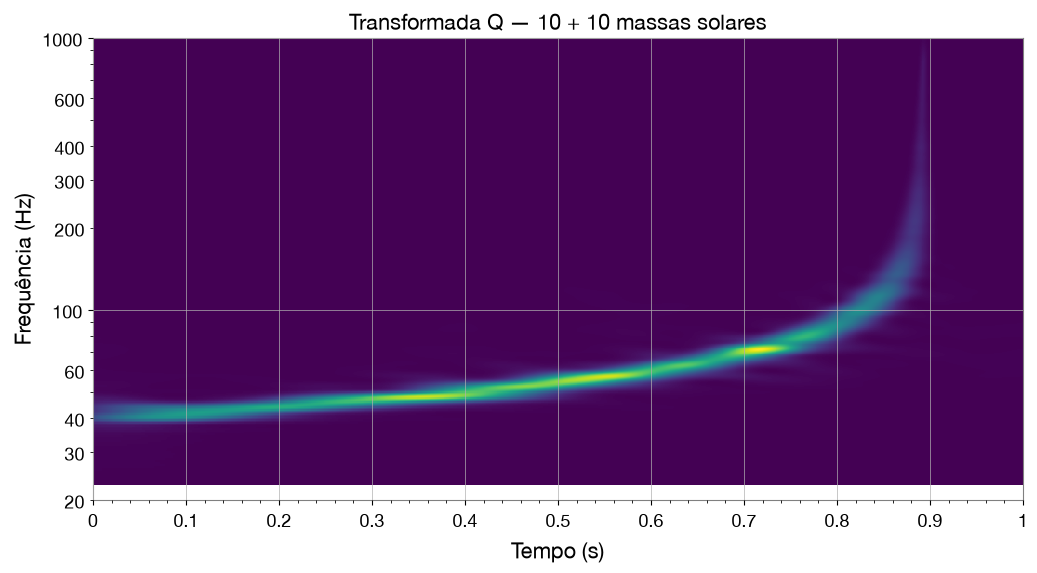

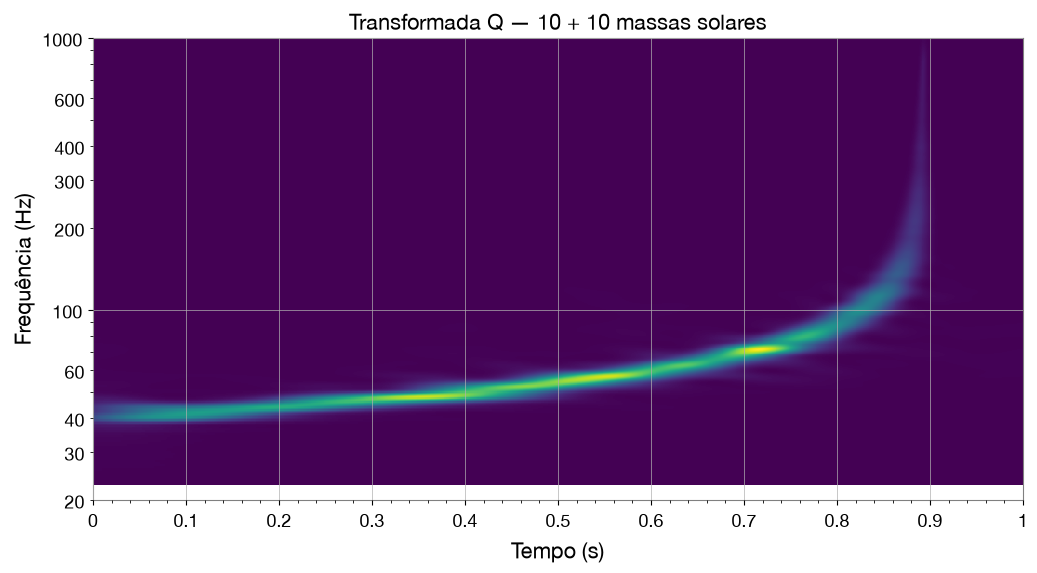

In [2]:
# -- Transformada Q do sistema original (10 + 10)
q10 = data10.q_transform(outseg=(4, 5), qrange=(10, 30))
fig_q10 = q10.plot()
ax_q10 = fig_q10.gca()
ax_q10.set_xscale('seconds')
ax_q10.set_yscale('log')
ax_q10.set_ylim(20, 1000)
ax_q10.set_xlabel('Tempo (s)')
ax_q10.set_ylabel('Frequência (Hz)')
ax_q10.set_title('Transformada Q — 10 + 10 massas solares')
fig_q10

## Pratique com Python

### 1. Gerar os mesmos gráficos para `mass1 = mass2 = 30`

Alteramos **apenas as massas**, mantendo a frequência de amostragem, o modelo, a distância, a frequência inicial e a realização de ruído iguais aos do sistema original.

A comparação é feita na **mesma janela temporal de 4 a 5 s** e na **mesma faixa de frequências de 20 a 1000 Hz**.

In [4]:
# -- Nova forma de onda: 30 + 30 massas solares
hp30, hc30 = get_td_waveform(
    approximant=apx, mass1=30, mass2=30,
    delta_t=1.0/fs, distance=distancia, f_lower=f_inicial
)
cbc30 = TimeSeries(np.asarray(hp30), dt=1/fs, t0=t0)
data30 = noise.inject(cbc30)

pico30 = t0 + np.argmax(np.abs(np.asarray(hp30))) / fs
print(f'Sistema 30 + 30: duração = {len(hp30)/fs:.3f} s')
print(f'Instante aproximado de maior amplitude: {pico30:.3f} s')

# -- Comparar a duração das formas de onda simuladas
print(f'Sistema 10 + 10: {len(hp10)} amostras')
print(f'Sistema 30 + 30: {len(hp30)} amostras')

Sistema 30 + 30: duração = 0.214 s
Instante aproximado de maior amplitude: 4.114 s
Sistema 10 + 10: 3789 amostras
Sistema 30 + 30: 875 amostras


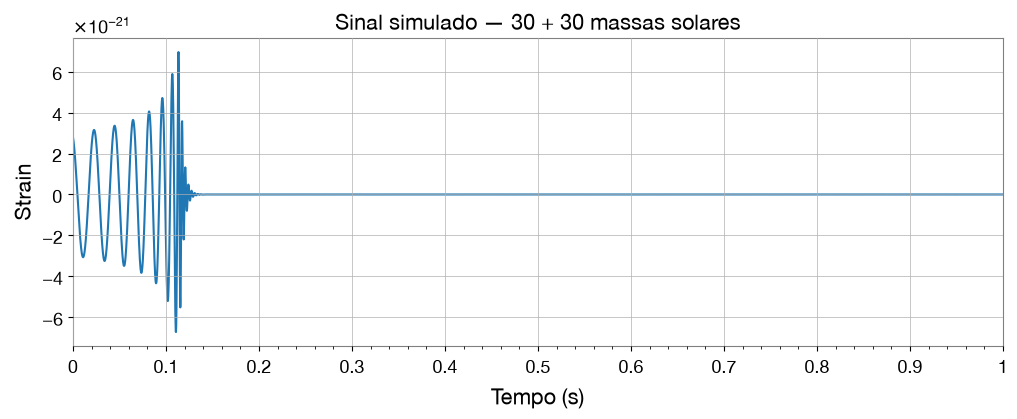

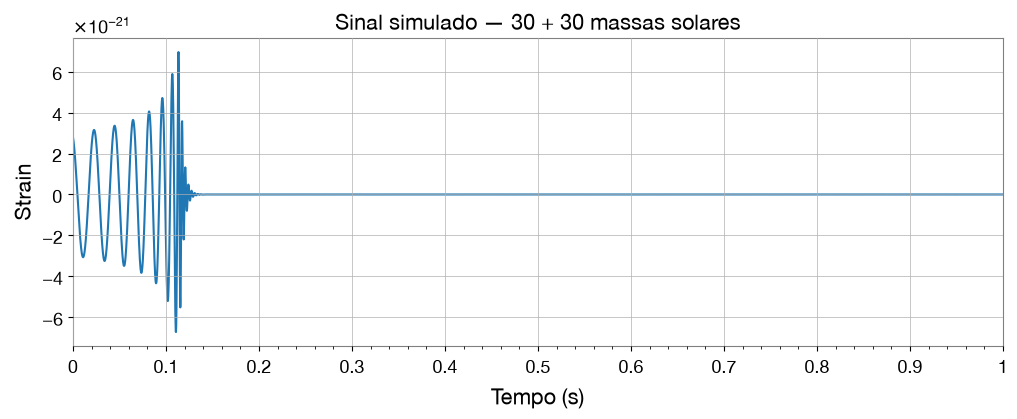

In [5]:
# -- Sinal no domínio do tempo — sistema de maior massa
fig30 = data30.plot(xlim=(4, 5))
ax30 = fig30.gca()
ax30.set_xlabel('Tempo (s)')
ax30.set_ylabel('Strain')
ax30.set_title('Sinal simulado — 30 + 30 massas solares')
fig30

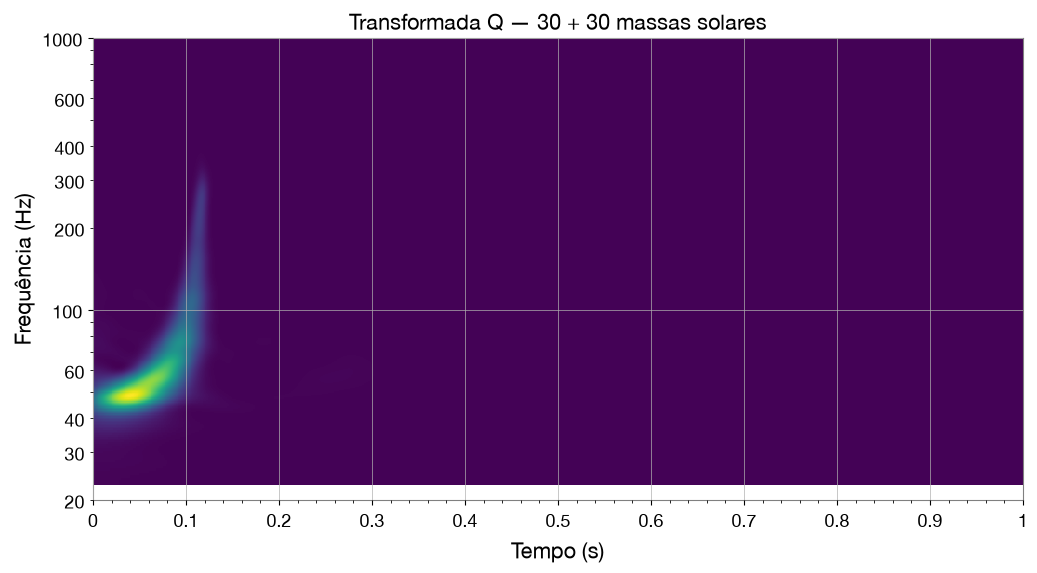

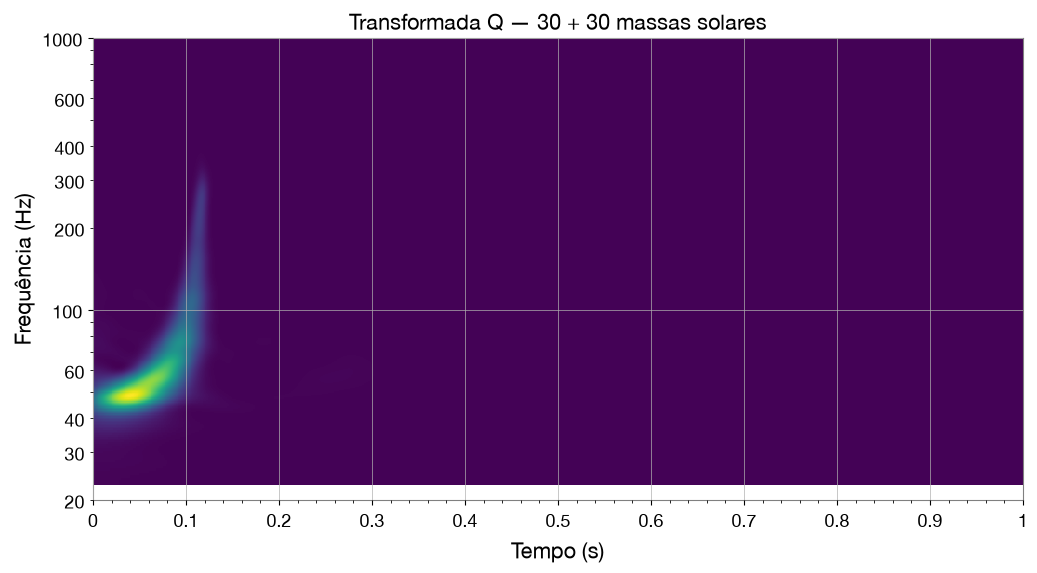

In [6]:
# -- Transformada Q do sistema de maior massa
q30 = data30.q_transform(outseg=(4, 5), qrange=(10, 30))
fig_q30 = q30.plot()
ax_q30 = fig_q30.gca()
ax_q30.set_xscale('seconds')
ax_q30.set_yscale('log')
ax_q30.set_ylim(20, 1000)
ax_q30.set_xlabel('Tempo (s)')
ax_q30.set_ylabel('Frequência (Hz)')
ax_q30.set_title('Transformada Q — 30 + 30 massas solares')
fig_q30

### Comparação direta no domínio do tempo

As duas formas de onda são colocadas no **mesmo gráfico**, usando o mesmo ruído e os mesmos limites de tempo. Como ambas começam em 4 s, mas possuem durações diferentes, **seus picos ocorrem em instantes distintos**. Isso não significa que uma fusão deva acontecer antes da outra na natureza: é apenas uma escolha de alinhamento dos sinais simulados.

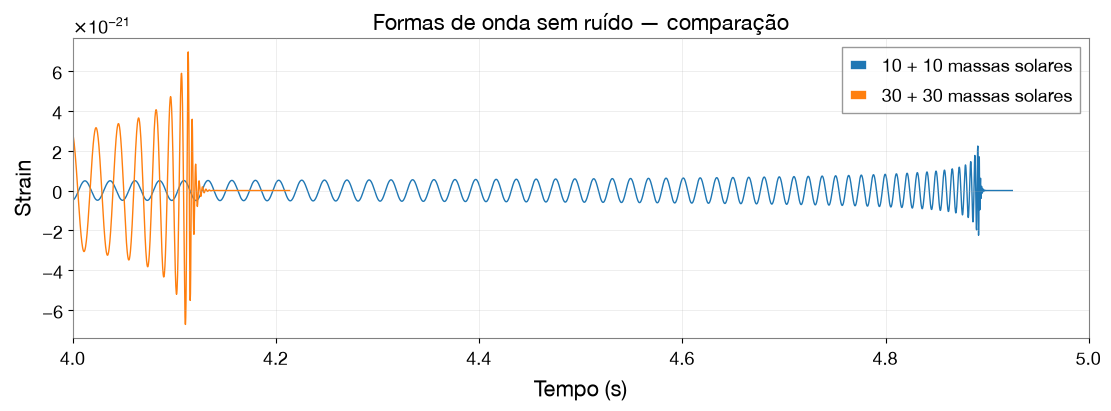

In [7]:
# -- Comparar as duas formas de onda sem ruído, preservando a fase original
# -- para destacar as diferenças de duração e de frequência

t10 = t0 + np.arange(len(hp10)) / fs
t30 = t0 + np.arange(len(hp30)) / fs

plt.figure(layout='constrained')
plt.plot(t10, np.asarray(hp10), lw=1, label='10 + 10 massas solares')
plt.plot(t30, np.asarray(hp30), lw=1, label='30 + 30 massas solares')
plt.xlim(4, 5)
plt.xlabel('Tempo (s)')
plt.ylabel('Strain')
plt.title('Formas de onda sem ruído — comparação')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2. Quais diferenças se observam entre os sistemas?

**Resposta esperada:**

1. **Duração:** começando na mesma frequência de 40 Hz, o sinal do sistema **30 + 30** permanece menos tempo na fase de inspiração. O sistema **10 + 10** apresenta um *chirp* mais longo, com mais ciclos observáveis.
2. **Frequência característica próxima da fusão:** o sistema **10 + 10** alcança frequências mais altas. O sistema mais massivo termina a inspiração em frequências mais baixas.
3. **Espectrograma:** no sistema **30 + 30**, a faixa ascendente é mais curta e concentrada em um intervalo menor de tempo; no sistema **10 + 10**, ela percorre um intervalo maior de tempo e se estende a frequências mais elevadas.
4. **Amplitude:** a comparação direta depende também da distância, da orientação e dos parâmetros escolhidos. Como mantivemos a **mesma distância (100 Mpc)** e a mesma configuração de geração, os gráficos permitem comparar as amplitudes produzidas especificamente neste exemplo. A cor da transformada Q não deve, por si só, ser interpretada como uma medida de amplitude física absoluta.

Como referência aproximada, a escala de frequência próxima do fim da inspiração varia inversamente com a massa total. Para buracos negros sem rotação, a aproximação pela órbita circular estável mais interna fornece:

$$f_{\mathrm{GW,ISCO}}\approx\frac{4400\ \mathrm{Hz}}{M/M_\odot}.$$

Isso corresponde a cerca de **220 Hz** para massa total de $20\,M_\odot$ e **73 Hz** para $60\,M_\odot$. Esses são **valores ilustrativos de escala**, não uma leitura exata do pico da transformada Q nem a frequência final determinada pelo modelo `SEOBNRv2`.

## Conclusão

A transformada Q permite observar no plano tempo-frequência a evolução de um *chirp*. A frequência aumenta porque os corpos se aproximam durante a inspiração. Ao iniciar a análise na mesma frequência de 40 Hz, o sistema **mais massivo** produz um sinal **mais curto**, cuja fase final ocorre em **frequências características menores** do que as do sistema menos massivo.

**Nota de execução:** o gabarito recria os sinais com `PyCBC` e os espectrogramas com `GWpy`. As respostas numéricas das perguntas 1 e 2 são **estimativas visuais** baseadas no exemplo original. Para obter resultados exatos de uma análise específica, seria necessário definir um método de estimação de frequência e sua incerteza.